# > CELLULE 1: Imports + configuration Kaggle>  

In [1]:
# CELLULE 1 : Imports + configuration Kaggle

import os
import numpy as np
import pandas as pd
import pydicom
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

# Détection du GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device utilisé : {device}")

# Chemin du dataset RSNA
DATA_DIR = "/kaggle/input/competitions/rsna-pneumonia-detection-challenge"

# Fichiers du dataset
TRAIN_LABELS_CSV = os.path.join(DATA_DIR, "stage_2_train_labels.csv")
TRAIN_IMAGES_DIR = os.path.join(DATA_DIR, "stage_2_train_images")

print(f"Dataset utilisé : {DATA_DIR}")
print(f"CSV des labels : {TRAIN_LABELS_CSV}")
print(f"Dossier images : {TRAIN_IMAGES_DIR}")

# Vérification
print("\nCSV existe :", os.path.exists(TRAIN_LABELS_CSV))
print("Dossier images existe :", os.path.exists(TRAIN_IMAGES_DIR))

Device utilisé : cuda
Dataset utilisé : /kaggle/input/competitions/rsna-pneumonia-detection-challenge
CSV des labels : /kaggle/input/competitions/rsna-pneumonia-detection-challenge/stage_2_train_labels.csv
Dossier images : /kaggle/input/competitions/rsna-pneumonia-detection-challenge/stage_2_train_images

CSV existe : True
Dossier images existe : True


# >CELLULE 2 : Exploration du dataset

In [2]:
df = pd.read_csv(TRAIN_LABELS_CSV)

print("===== DATASET ORIGINAL RSNA =====")

nb_bounding_boxes = int(df["Target"].sum())
nb_images = df["patientId"].nunique()
nb_images_positives = df[df["Target"] == 1]["patientId"].nunique()
nb_images_negatives = df[df["Target"] == 0]["patientId"].nunique()

print(f"Total patients : {nb_images}")
print(f"Patients positifs : {nb_images_positives}")
print(f"Patients négatifs : {nb_images_negatives}")
print(f"Total bounding boxes : {nb_bounding_boxes}")

df_positive = df[df["Target"] == 1].copy()

print("\n===== DATASET POSITIF =====")
print(f"Patients positifs retenus : {df_positive['patientId'].nunique()}")
print(f"Nombre de lignes / annotations : {len(df_positive)}")

bbox_per_patient = df_positive.groupby("patientId").size()


===== DATASET ORIGINAL RSNA =====
Total patients : 26684
Patients positifs : 6012
Patients négatifs : 20672
Total bounding boxes : 9555

===== DATASET POSITIF =====
Patients positifs retenus : 6012
Nombre de lignes / annotations : 9555


# >CELLULE 3 : Visualisation + création des masques

Figure successfully saved: original_images_and_pseudo_masks_3_cases.png


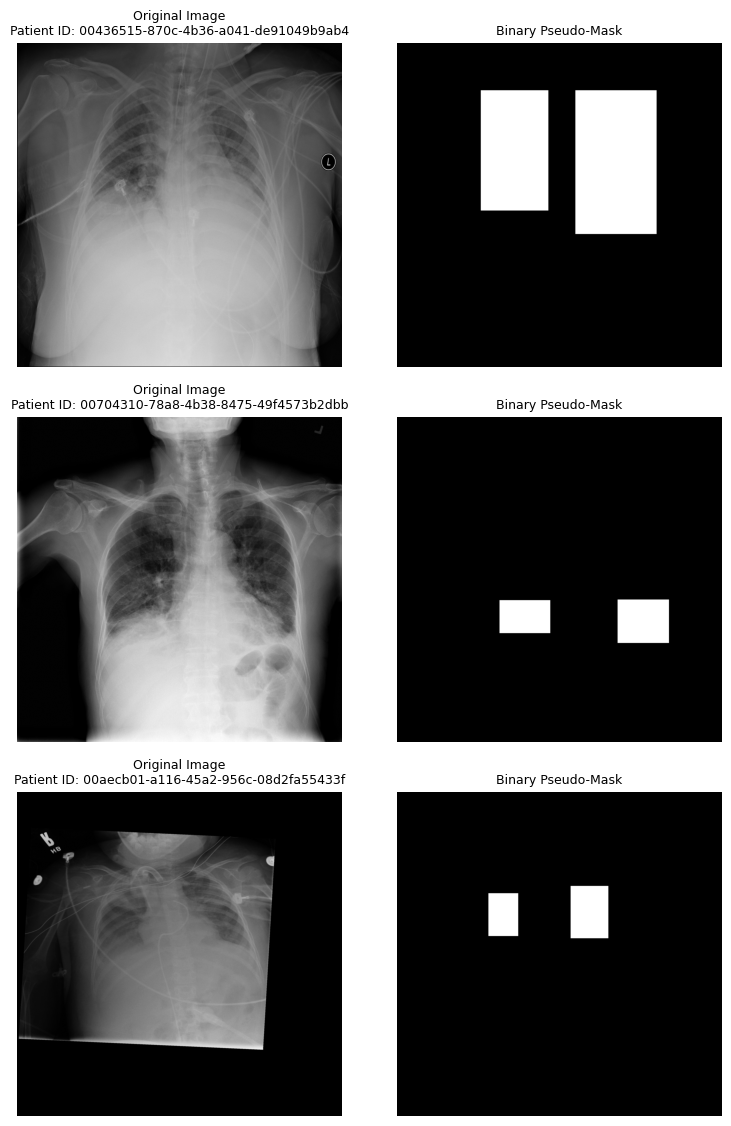

In [3]:
import os
import numpy as np
import pydicom
from pydicom.pixel_data_handlers.util import apply_voi_lut
import matplotlib.pyplot as plt

# 1. Load DICOM image (VOI LUT + polarity correction + normalization)
def load_dicom_image(patient_id):
    path = os.path.join(TRAIN_IMAGES_DIR, f"{patient_id}.dcm")
    dcm = pydicom.dcmread(path)

    # Apply VOI LUT (contrast windowing)
    img = apply_voi_lut(dcm.pixel_array, dcm)

    # Correct MONOCHROME1 polarity (so opacities appear bright)
    if getattr(dcm, "PhotometricInterpretation", "") == "MONOCHROME1":
        img = np.amax(img) - img

    # Normalize to [0, 1]
    img = img.astype(np.float32)
    img = (img - img.min()) / (img.max() - img.min() + 1e-8)

    return img

# 2. Convert bounding boxes to a single binary pseudo-mask
def bboxes_to_mask(patient_id, df_source, image_shape=(1024, 1024)):
    mask = np.zeros(image_shape, dtype=np.uint8)
    boxes = df_source[(df_source["patientId"] == patient_id) & (df_source["Target"] == 1)]

    for _, row in boxes.iterrows():
        x = int(row["x"])
        y = int(row["y"])
        w = int(row["width"])
        h = int(row["height"])
        mask[y:y+h, x:x+w] = 1

    return mask

# 3. Visualization of 3 representative positive cases
positive_ids = df_positive["patientId"].unique()[:3]

fig, axes = plt.subplots(
    nrows=len(positive_ids),
    ncols=2,
    figsize=(8, 3.8 * len(positive_ids)),
    facecolor="white"
)

for i, patient_id in enumerate(positive_ids):
    image = load_dicom_image(patient_id)
    mask = bboxes_to_mask(patient_id, df_positive, image_shape=image.shape)

    # Column 1: Original radiograph
    axes[i, 0].imshow(image, cmap="gray")
    axes[i, 0].set_title(f"Original Image\nPatient ID: {patient_id}", fontsize=9, pad=6)
    axes[i, 0].axis("off")

    # Column 2: Binary pseudo-mask
    axes[i, 1].imshow(mask, cmap="gray", vmin=0, vmax=1)
    axes[i, 1].set_title("Binary Pseudo-Mask", fontsize=9, pad=6)
    axes[i, 1].axis("off")

plt.tight_layout(pad=1.2)

# Save high-quality figure for the LaTeX document
output_path = "original_images_and_pseudo_masks_3_cases.png"
plt.savefig(output_path, dpi=300, bbox_inches="tight", facecolor="white")
print(f"Figure successfully saved: {output_path}")

plt.show()

# >CELLULE 4 : Dataset et DataLoaders

In [4]:
import cv2
from sklearn.model_selection import train_test_split

# Test avec un batch factice
IMG_SIZE = 256

class PneumoniaDataset(Dataset):
    def __init__(self, patient_ids, df_source, images_dir, img_size=IMG_SIZE):
        self.patient_ids = list(patient_ids)
        self.df_source = df_source
        self.images_dir = images_dir
        self.img_size = img_size

    def __len__(self):
        return len(self.patient_ids)

    def __getitem__(self, idx):
        patient_id = self.patient_ids[idx]

        # Image (déjà dans [0, 1] grâce à load_dicom_image)
        image = load_dicom_image(patient_id)
        mask = bboxes_to_mask(patient_id, self.df_source, image_shape=image.shape).astype(np.float32)

        # Resize 256x256
        image = cv2.resize(image, (self.img_size, self.img_size))
        mask = cv2.resize(mask, (self.img_size, self.img_size), interpolation=cv2.INTER_NEAREST)

        # Tensors : (1, H, W)
        image = torch.tensor(image, dtype=torch.float32).unsqueeze(0)
        mask = torch.tensor(mask, dtype=torch.float32).unsqueeze(0)

        return image, mask

# Split
all_patient_ids = df_positive["patientId"].unique()

train_ids, temp_ids = train_test_split(all_patient_ids, test_size=0.3, random_state=42)
val_ids, test_ids = train_test_split(temp_ids, test_size=0.5, random_state=42)

print(f"Train : {len(train_ids)} images (70%)")
print(f"Validation : {len(val_ids)} images (15%)")
print(f"Test : {len(test_ids)} images (15%)")

# Datasets et DataLoaders
train_dataset = PneumoniaDataset(train_ids, df_positive, TRAIN_IMAGES_DIR)
val_dataset = PneumoniaDataset(val_ids, df_positive, TRAIN_IMAGES_DIR)
test_dataset = PneumoniaDataset(test_ids, df_positive, TRAIN_IMAGES_DIR)

BATCH_SIZE = 16  # 16 est idéal et plus stable que 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

Train : 4208 images (70%)
Validation : 902 images (15%)
Test : 902 images (15%)


# > CELLULE 5 :  Modèle U-Net From Scratch

In [5]:
# SimpleUNet — définition de l'architecture

def conv_block(in_channels, out_channels):
    return nn.Sequential(
        nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
        nn.BatchNorm2d(out_channels),
        nn.ReLU(inplace=True),
        nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
        nn.BatchNorm2d(out_channels),
        nn.ReLU(inplace=True),
    )

class SimpleUNet(nn.Module):
    def __init__(self):
        super().__init__()

        # Encoder
        self.enc1 = conv_block(1, 16)
        self.enc2 = conv_block(16, 32)
        self.enc3 = conv_block(32, 64)
        self.pool = nn.MaxPool2d(2)

        # Bottleneck
        self.bottleneck = conv_block(64, 128)

        # Decoder
        self.up3 = nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2)
        self.dec3 = conv_block(128, 64)

        self.up2 = nn.ConvTranspose2d(64, 32, kernel_size=2, stride=2)
        self.dec2 = conv_block(64, 32)

        self.up1 = nn.ConvTranspose2d(32, 16, kernel_size=2, stride=2)
        self.dec1 = conv_block(32, 16)

        self.out_conv = nn.Conv2d(16, 1, kernel_size=1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))

        b = self.bottleneck(self.pool(e3))

        d3 = self.up3(b)
        d3 = self.dec3(torch.cat([d3, e3], dim=1))

        d2 = self.up2(d3)
        d2 = self.dec2(torch.cat([d2, e2], dim=1))

        d1 = self.up1(d2)
        d1 = self.dec1(torch.cat([d1, e1], dim=1))

        return self.out_conv(d1)

print(f"Paramètres SimpleUNet : {sum(p.numel() for p in SimpleUNet().parameters()):,}")


Paramètres SimpleUNet : 483,153


In [6]:
# Fonctions communes : Loss, IoU et entraînement avec contrôle de l'overfitting

import time
import copy
import torch.optim as optim
from tqdm.auto import tqdm

def dice_loss(pred, target, eps=1e-7):
    pred = torch.sigmoid(pred)
    intersection = (pred * target).sum(dim=(1, 2, 3))
    union = pred.sum(dim=(1, 2, 3)) + target.sum(dim=(1, 2, 3))
    dice = (2 * intersection + eps) / (union + eps)
    return 1 - dice.mean()

bce_loss = nn.BCEWithLogitsLoss()

def combined_loss(pred, target):
    return 0.5 * bce_loss(pred, target) + 0.5 * dice_loss(pred, target)

def compute_iou(pred, target, threshold=0.5, eps=1e-7):
    pred = (torch.sigmoid(pred) > threshold).float()
    has_positive = target.sum(dim=(1, 2, 3)) > 0

    if has_positive.sum() == 0:
        return None

    pred_pos = pred[has_positive]
    target_pos = target[has_positive]

    intersection = (pred_pos * target_pos).sum(dim=(1, 2, 3))
    union = pred_pos.sum(dim=(1, 2, 3)) + target_pos.sum(dim=(1, 2, 3)) - intersection
    return ((intersection + eps) / (union + eps)).mean().item()

def compute_dice_score(model, loader, threshold=0.5, eps=1e-7):
    model.eval()
    total = 0.0
    count = 0

    with torch.no_grad():
        for images, masks in loader:
            images, masks = images.to(device), masks.to(device)
            preds = (torch.sigmoid(model(images)) > threshold).float()

            intersection = (preds * masks).sum(dim=(1, 2, 3))
            dice = (
                2 * intersection + eps
            ) / (
                preds.sum(dim=(1, 2, 3)) +
                masks.sum(dim=(1, 2, 3)) +
                eps
            )

            total += dice.sum().item()
            count += len(dice)

    return total / count

def train_model_robust(
    model,
    train_loader,
    val_loader,
    num_epochs,
    save_path,
    lr,
    weight_decay=5e-4,
    scheduler_patience=2,
    early_stopping_patience=4,
    min_delta=1e-4
):
    optimizer = optim.AdamW(
        model.parameters(),
        lr=lr,
        weight_decay=weight_decay
    )

    scheduler = optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="max",
        factor=0.5,
        patience=scheduler_patience,
        threshold=min_delta,
        threshold_mode="abs",
        min_lr=1e-6
    )

    history = {
        "train_loss": [],
        "val_loss": [],
        "val_iou": [],
        "lr": []
    }

    best_iou = -1.0
    best_epoch = 0
    no_improvement = 0

    for epoch in range(num_epochs):
        start = time.time()

        # ---------- TRAIN ----------
        model.train()
        train_loss = 0.0

        for images, masks in tqdm(
            train_loader,
            desc=f"Epoch {epoch+1}/{num_epochs}"
        ):
            images = images.to(device, non_blocking=True)
            masks = masks.to(device, non_blocking=True)

            optimizer.zero_grad(set_to_none=True)

            preds = model(images)
            loss = combined_loss(preds, masks)

            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()

            train_loss += loss.item()

        train_loss /= len(train_loader)

        # ---------- VALIDATION ----------
        model.eval()
        val_loss = 0.0
        val_ious = []

        with torch.no_grad():
            for images, masks in val_loader:
                images = images.to(device, non_blocking=True)
                masks = masks.to(device, non_blocking=True)

                preds = model(images)
                val_loss += combined_loss(preds, masks).item()

                batch_iou = compute_iou(preds, masks)
                if batch_iou is not None:
                    val_ious.append(batch_iou)

        val_loss /= len(val_loader)
        val_iou = float(np.mean(val_ious)) if val_ious else 0.0

        scheduler.step(val_iou)
        current_lr = optimizer.param_groups[0]["lr"]

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_iou"].append(val_iou)
        history["lr"].append(current_lr)

        if val_iou > best_iou + min_delta:
            best_iou = val_iou
            best_epoch = epoch + 1
            no_improvement = 0
            torch.save(model.state_dict(), save_path)
            status = "BEST"
        else:
            no_improvement += 1
            status = ""

        print(
            f"Epoch {epoch+1:02d}/{num_epochs} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val IoU: {val_iou:.4f} | "
            f"LR: {current_lr:.2e} | "
            f"{status} | {time.time()-start:.1f}s"
        )

        if no_improvement >= early_stopping_patience:
            print(f"Early stopping à l'epoch {epoch+1}.")
            break

    model.load_state_dict(torch.load(save_path, map_location=device))
    return model, history, best_iou, best_epoch

def plot_model_history(history, model_name):
    epochs = range(1, len(history["train_loss"]) + 1)

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].plot(epochs, history["train_loss"], label="Train Loss")
    axes[0].plot(epochs, history["val_loss"], label="Validation Loss")
    axes[0].set_title(f"{model_name} — Loss")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Loss")
    axes[0].legend()
    axes[0].grid(alpha=0.3)

    axes[1].plot(epochs, history["val_iou"], label="Validation IoU")
    axes[1].set_title(f"{model_name} — Validation IoU")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("IoU")
    axes[1].legend()
    axes[1].grid(alpha=0.3)

    plt.tight_layout()
    plt.savefig(
        f"{model_name.replace(' ', '_').lower()}_curves.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()

def evaluate_model(model, name):
    model.eval()
    test_ious = []

    with torch.no_grad():
        for images, masks in test_loader:
            images, masks = images.to(device), masks.to(device)
            batch_iou = compute_iou(model(images), masks)
            if batch_iou is not None:
                test_ious.append(batch_iou)

    test_iou = float(np.mean(test_ious)) if test_ious else 0.0
    test_dice = compute_dice_score(model, test_loader)

    print(f"{name}")
    print(f"Test IoU  : {test_iou:.4f}")
    print(f"Test Dice : {test_dice:.4f}")

    return test_iou, test_dice

def show_prediction(model, title):
    images, masks = next(iter(test_loader))
    images_gpu = images.to(device)

    with torch.no_grad():
        preds = (torch.sigmoid(model(images_gpu)) > 0.5).cpu()

    n = min(3, len(images))
    fig, axes = plt.subplots(n, 3, figsize=(10, 3.5 * n))
    if n == 1:
        axes = np.expand_dims(axes, axis=0)

    for i in range(n):
        axes[i, 0].imshow(images[i, 0], cmap="gray")
        axes[i, 0].set_title("Chest X-ray")
        axes[i, 0].axis("off")

        axes[i, 1].imshow(masks[i, 0], cmap="gray")
        axes[i, 1].set_title("Pseudo-mask")
        axes[i, 1].axis("off")

        axes[i, 2].imshow(preds[i, 0], cmap="gray")
        axes[i, 2].set_title("Prediction")
        axes[i, 2].axis("off")

    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


> Configuration commune — ResNet-18 U-Net> 

In [7]:
!pip install segmentation-models-pytorch -q
import segmentation_models_pytorch as smp
print("segmentation_models_pytorch chargé.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 5.7 MB/s eta 0:00:00
segmentation_models_pytorch chargé.


# 1. SimpleUNet — From Scratch

In [8]:

model_simple_scratch = SimpleUNet().to(device)

model_simple_scratch, history_simple_scratch, best_simple_scratch, epoch_simple_scratch = train_model_robust(
    model_simple_scratch,
    train_loader,
    val_loader,
    num_epochs=10,
    save_path="BEST_simpleUNet_scratch.pth",
    lr=3e-4
)

test_iou_simple_scratch, dice_simple_scratch = evaluate_model(
    model_simple_scratch,
    "SimpleUNet — From Scratch"
)

print(f"Paramètres : {sum(p.numel() for p in model_simple_scratch.parameters()):,}")
print(f"Best Val IoU : {best_simple_scratch:.4f}")
print(f"Best Epoch : {epoch_simple_scratch}")


Epoch 1/10:   0%|          | 0/263 [00:00<?, ?it/s]

Epoch 01/10 | Train Loss: 0.6553 | Val Loss: 0.5696 | Val IoU: 0.3643 | LR: 3.00e-04 | BEST | 164.7s


Epoch 2/10:   0%|          | 0/263 [00:00<?, ?it/s]

Epoch 02/10 | Train Loss: 0.5264 | Val Loss: 0.4790 | Val IoU: 0.4014 | LR: 3.00e-04 | BEST | 96.0s


Epoch 3/10:   0%|          | 0/263 [00:00<?, ?it/s]

...

Epoch 08/10 | Train Loss: 0.3295 | Val Loss: 0.3362 | Val IoU: 0.4566 | LR: 3.00e-04 | BEST | 94.3s


Epoch 9/10:   0%|          | 0/263 [00:00<?, ?it/s]

Epoch 09/10 | Train Loss: 0.3219 | Val Loss: 0.3340 | Val IoU: 0.4596 | LR: 3.00e-04 | BEST | 93.9s


Epoch 10/10:   0%|          | 0/263 [00:00<?, ?it/s]

Epoch 10/10 | Train Loss: 0.3168 | Val Loss: 0.3295 | Val IoU: 0.4622 | LR: 3.00e-04 | BEST | 93.9s
SimpleUNet — From Scratch
Test IoU  : 0.4420
Test Dice : 0.5857
Paramètres : 483,153
Best Val IoU : 0.4622
Best Epoch : 10


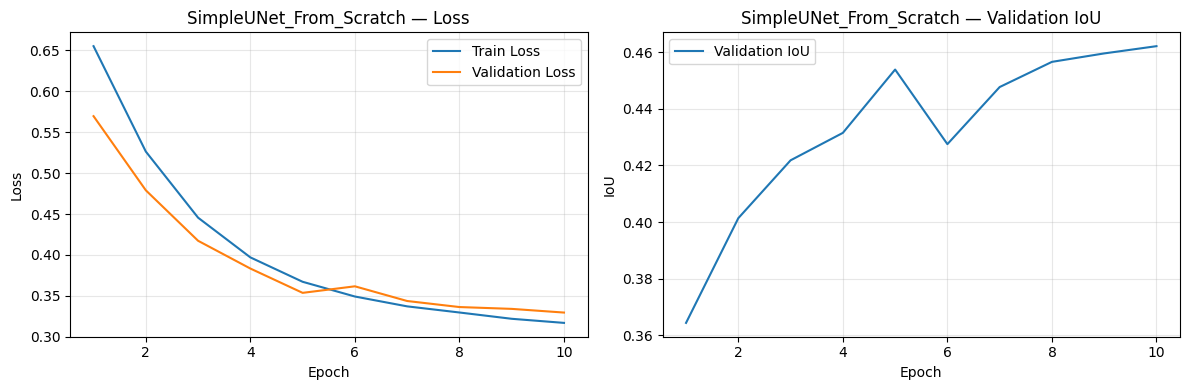

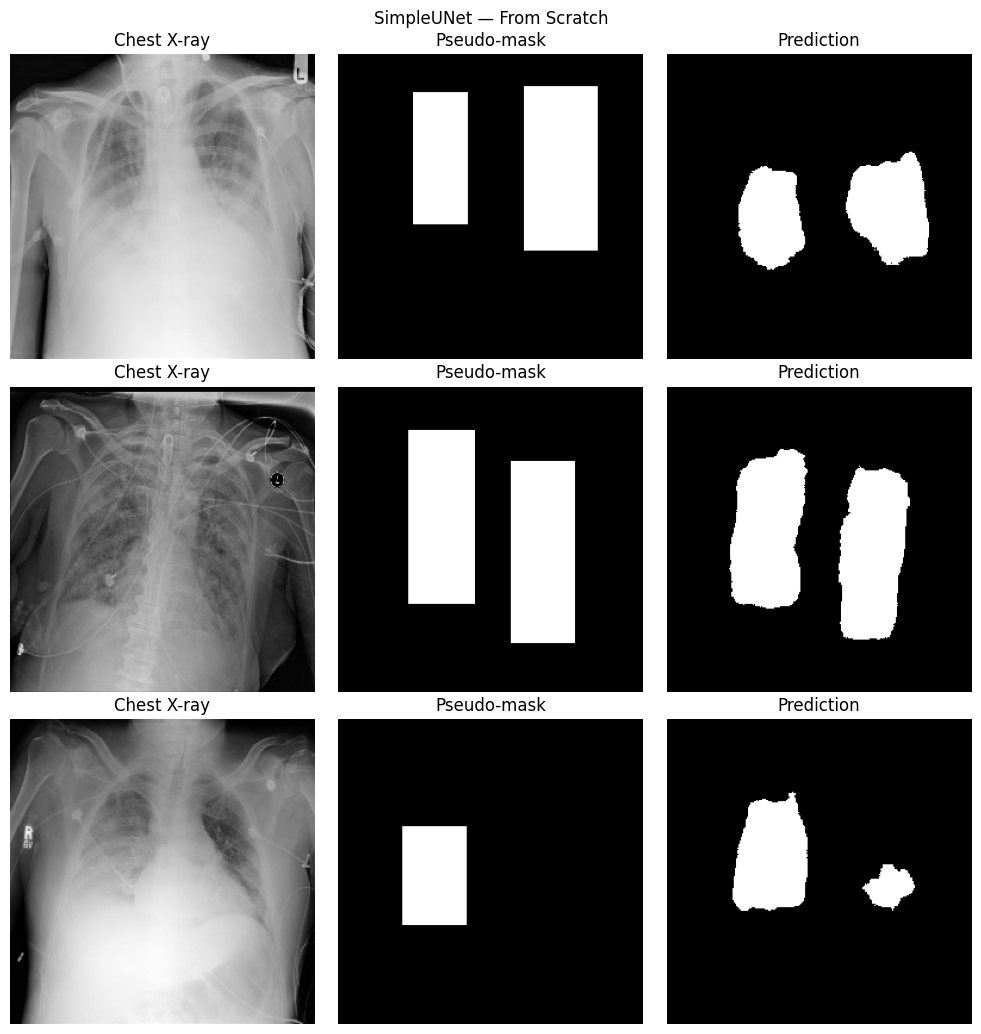

In [9]:
plot_model_history(history_simple_scratch, "SimpleUNet_From_Scratch")
show_prediction(model_simple_scratch, "SimpleUNet — From Scratch")

# 2. SimpleUNet — Fine-Tuning

In [10]:

model_simple_ft = SimpleUNet().to(device)
model_simple_ft.load_state_dict(
    torch.load("BEST_simpleUNet_scratch.pth", map_location=device)
)

model_simple_ft, history_simple_ft, best_simple_ft, epoch_simple_ft = train_model_robust(
    model_simple_ft,
    train_loader,
    val_loader,
    num_epochs=10,
    save_path="BEST_simpleUNet_finetuning.pth",
    lr=1e-4
)

test_iou_simple_ft, dice_simple_ft = evaluate_model(
    model_simple_ft,
    "SimpleUNet — Fine-Tuning"
)

print(f"Paramètres : {sum(p.numel() for p in model_simple_ft.parameters()):,}")
print(f"Best Val IoU : {best_simple_ft:.4f}")
print(f"Best Epoch : {epoch_simple_ft}")


Epoch 1/10:   0%|          | 0/263 [00:00<?, ?it/s]

Epoch 01/10 | Train Loss: 0.2986 | Val Loss: 0.3220 | Val IoU: 0.4704 | LR: 1.00e-04 | BEST | 94.0s


Epoch 2/10:   0%|          | 0/263 [00:00<?, ?it/s]

Epoch 02/10 | Train Loss: 0.2916 | Val Loss: 0.3226 | Val IoU: 0.4703 | LR: 1.00e-04 |  | 95.1s


Epoch 3/10:   0%|          | 0/263 [00:00<?, ?it/s]

Epoch 03/10 | Train Loss: 0.2873 | Val Loss: 0.3253 | Val IoU: 0.4670 | LR: 1.00e-04 |  | 94.2s


Epoch 4/10:   0%|          | 0/263 [00:00<?, ?it/s]

Epoch 04/10 | Train Loss: 0.2830 | Val Loss: 0.3271 | Val IoU: 0.4677 | LR: 5.00e-05 |  | 94.2s


Epoch 5/10:   0%|          | 0/263 [00:00<?, ?it/s]

Epoch 05/10 | Train Loss: 0.2736 | Val Loss: 0.3263 | Val IoU: 0.4664 | LR: 5.00e-05 |  | 94.1s
Early stopping à l'epoch 5.
SimpleUNet — Fine-Tuning
Test IoU  : 0.4551
Test Dice : 0.5985
Paramètres : 483,153
Best Val IoU : 0.4704
Best Epoch : 1


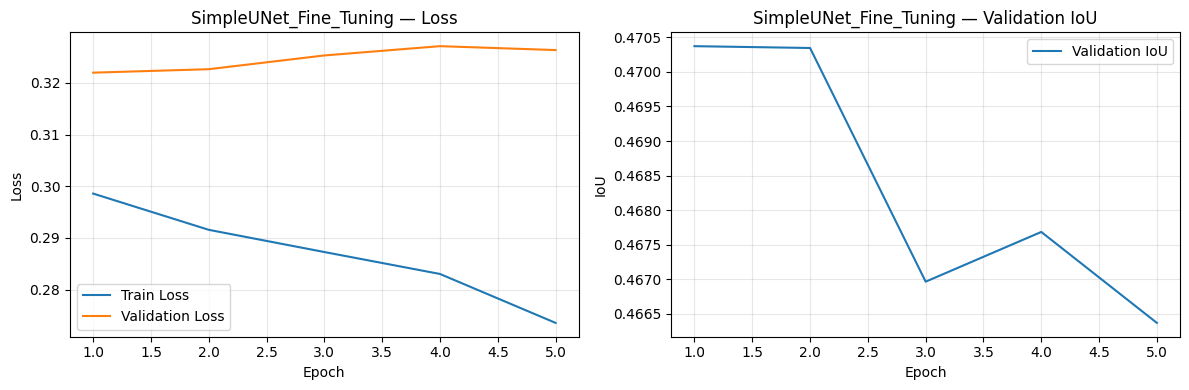

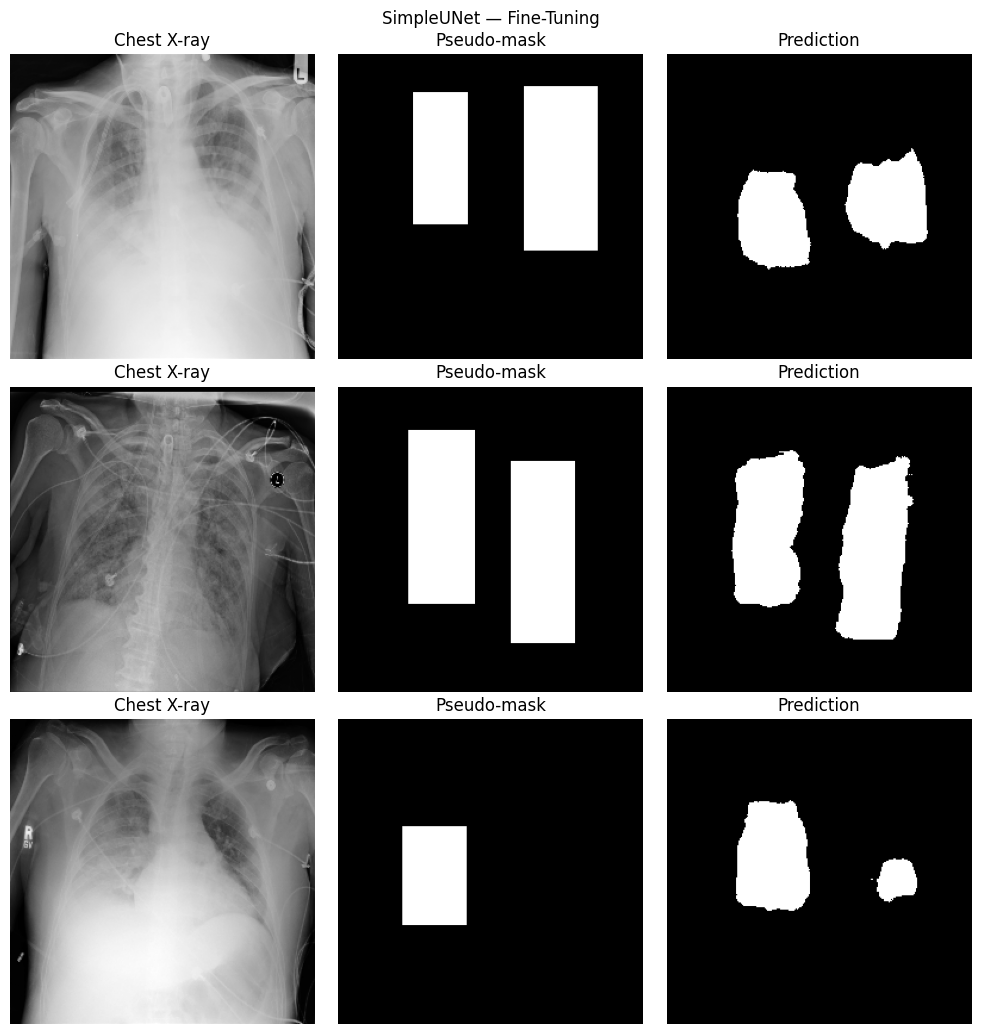

In [11]:
plot_model_history(history_simple_ft, "SimpleUNet_Fine_Tuning")
show_prediction(model_simple_ft, "SimpleUNet — Fine-Tuning")

# 3. ResNet-18 U-Net — From Scratch

In [12]:

model_resnet_scratch = smp.Unet(
    encoder_name="resnet18",
    encoder_weights=None,
    in_channels=1,
    classes=1
).to(device)

model_resnet_scratch, history_resnet_scratch, best_resnet_scratch, epoch_resnet_scratch = train_model_robust(
    model_resnet_scratch,
    train_loader,
    val_loader,
    num_epochs=10,
    save_path="BEST_resnet18_scratch.pth",
    lr=3e-4
)

test_iou_resnet_scratch, dice_resnet_scratch = evaluate_model(
    model_resnet_scratch,
    "ResNet-18 U-Net — From Scratch"
)

print(f"Paramètres : {sum(p.numel() for p in model_resnet_scratch.parameters()):,}")
print(f"Best Val IoU : {best_resnet_scratch:.4f}")
print(f"Best Epoch : {epoch_resnet_scratch}")


Epoch 1/10:   0%|          | 0/263 [00:00<?, ?it/s]

Epoch 01/10 | Train Loss: 0.4348 | Val Loss: 0.3813 | Val IoU: 0.3978 | LR: 3.00e-04 | BEST | 101.3s


Epoch 2/10:   0%|          | 0/263 [00:00<?, ?it/s]

Epoch 02/10 | Train Loss: 0.3425 | Val Loss: 0.3524 | Val IoU: 0.4289 | LR: 3.00e-04 | BEST | 101.4s


Epoch 3/10:   0%|          | 0/263 [00:00<?, ?it/s]

...

Epoch 08/10 | Train Loss: 0.2810 | Val Loss: 0.3142 | Val IoU: 0.4794 | LR: 3.00e-04 |  | 101.2s


Epoch 9/10:   0%|          | 0/263 [00:00<?, ?it/s]

Epoch 09/10 | Train Loss: 0.2684 | Val Loss: 0.3317 | Val IoU: 0.4726 | LR: 3.00e-04 |  | 101.4s


Epoch 10/10:   0%|          | 0/263 [00:00<?, ?it/s]

Epoch 10/10 | Train Loss: 0.2535 | Val Loss: 0.3357 | Val IoU: 0.4631 | LR: 1.50e-04 |  | 101.0s
ResNet-18 U-Net — From Scratch
Test IoU  : 0.4751
Test Dice : 0.6169
Paramètres : 14,321,937
Best Val IoU : 0.4829
Best Epoch : 7


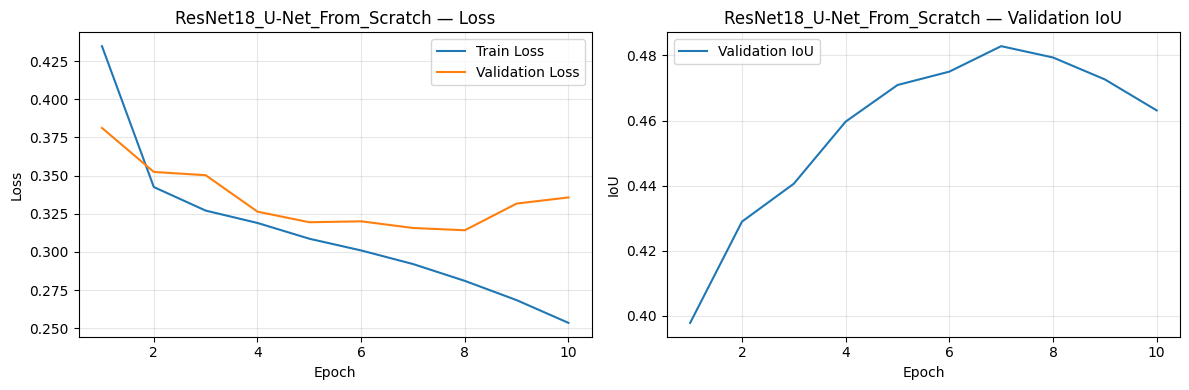

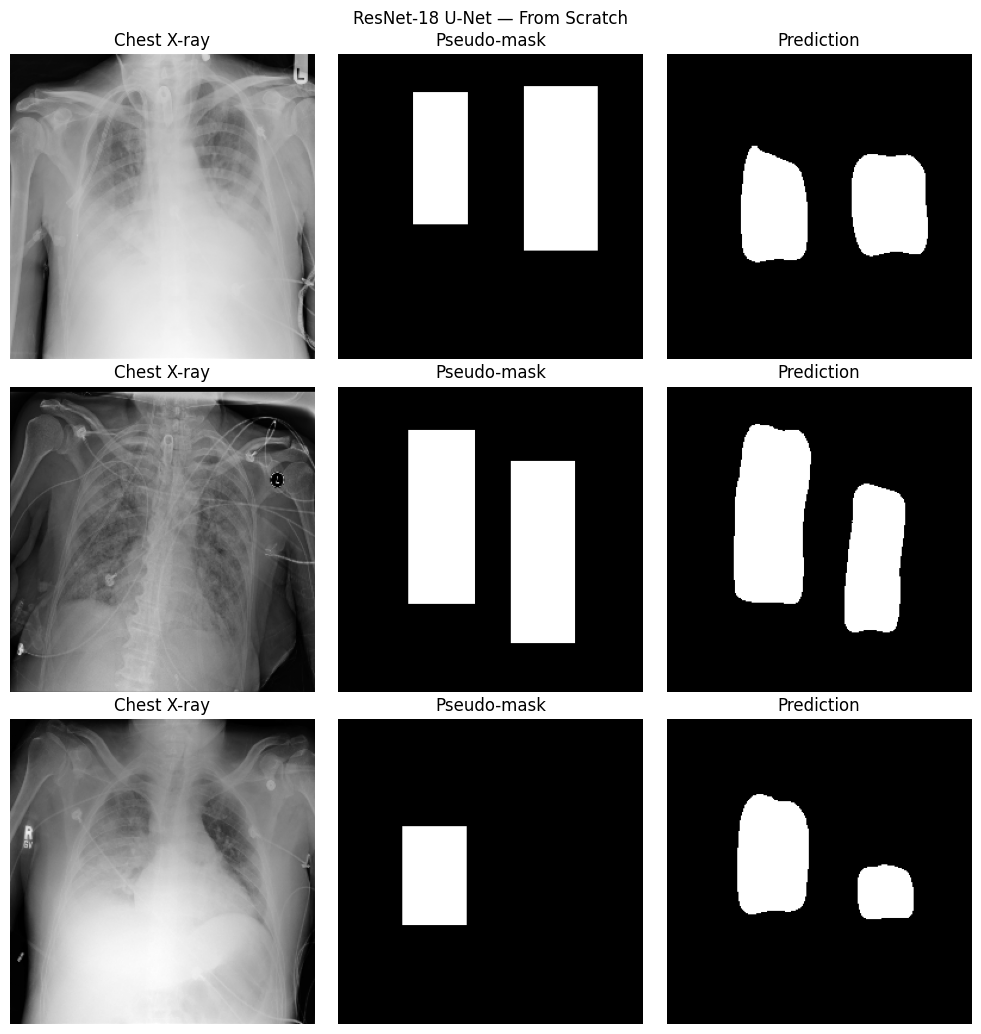

In [13]:
plot_model_history(history_resnet_scratch, "ResNet18_U-Net_From_Scratch")
show_prediction(model_resnet_scratch, "ResNet-18 U-Net — From Scratch")

# 4. ResNet-18 U-Net — Fine-Tuning

In [14]:

model_resnet_ft = smp.Unet(
    encoder_name="resnet18",
    encoder_weights="imagenet",
    in_channels=1,
    classes=1
).to(device)

model_resnet_ft, history_resnet_ft, best_resnet_ft, epoch_resnet_ft = train_model_robust(
    model_resnet_ft,
    train_loader,
    val_loader,
    num_epochs=10,
    save_path="BEST_resnet18_finetuning.pth",
    lr=1e-4
)

test_iou_resnet_ft, dice_resnet_ft = evaluate_model(
    model_resnet_ft,
    "ResNet-18 U-Net — Fine-Tuning ImageNet"
)

print(f"Paramètres : {sum(p.numel() for p in model_resnet_ft.parameters()):,}")
print(f"Best Val IoU : {best_resnet_ft:.4f}")
print(f"Best Epoch : {epoch_resnet_ft}")


config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/46.8M [00:00<?, ?B/s]

Epoch 1/10:   0%|          | 0/263 [00:00<?, ?it/s]

Epoch 01/10 | Train Loss: 0.5124 | Val Loss: 0.4038 | Val IoU: 0.4786 | LR: 1.00e-04 | BEST | 101.0s


Epoch 2/10:   0%|          | 0/263 [00:00<?, ?it/s]

...

Epoch 04/10 | Train Loss: 0.2505 | Val Loss: 0.3155 | Val IoU: 0.4939 | LR: 1.00e-04 |  | 101.4s


Epoch 5/10:   0%|          | 0/263 [00:00<?, ?it/s]

Epoch 05/10 | Train Loss: 0.2110 | Val Loss: 0.3343 | Val IoU: 0.4686 | LR: 5.00e-05 |  | 101.7s


Epoch 6/10:   0%|          | 0/263 [00:00<?, ?it/s]

Epoch 06/10 | Train Loss: 0.1650 | Val Loss: 0.3309 | Val IoU: 0.4794 | LR: 5.00e-05 |  | 101.8s
Early stopping à l'epoch 6.
ResNet-18 U-Net — Fine-Tuning ImageNet
Test IoU  : 0.4787
Test Dice : 0.6233
Paramètres : 14,321,937
Best Val IoU : 0.4981
Best Epoch : 2


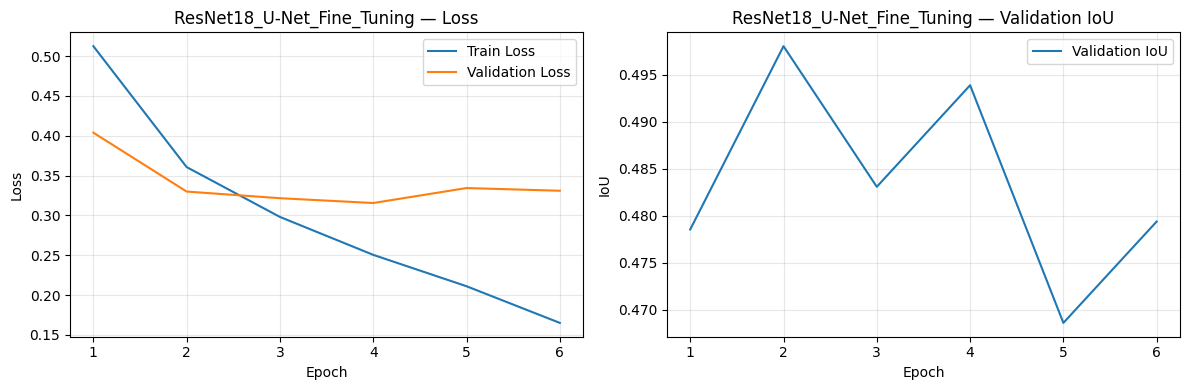

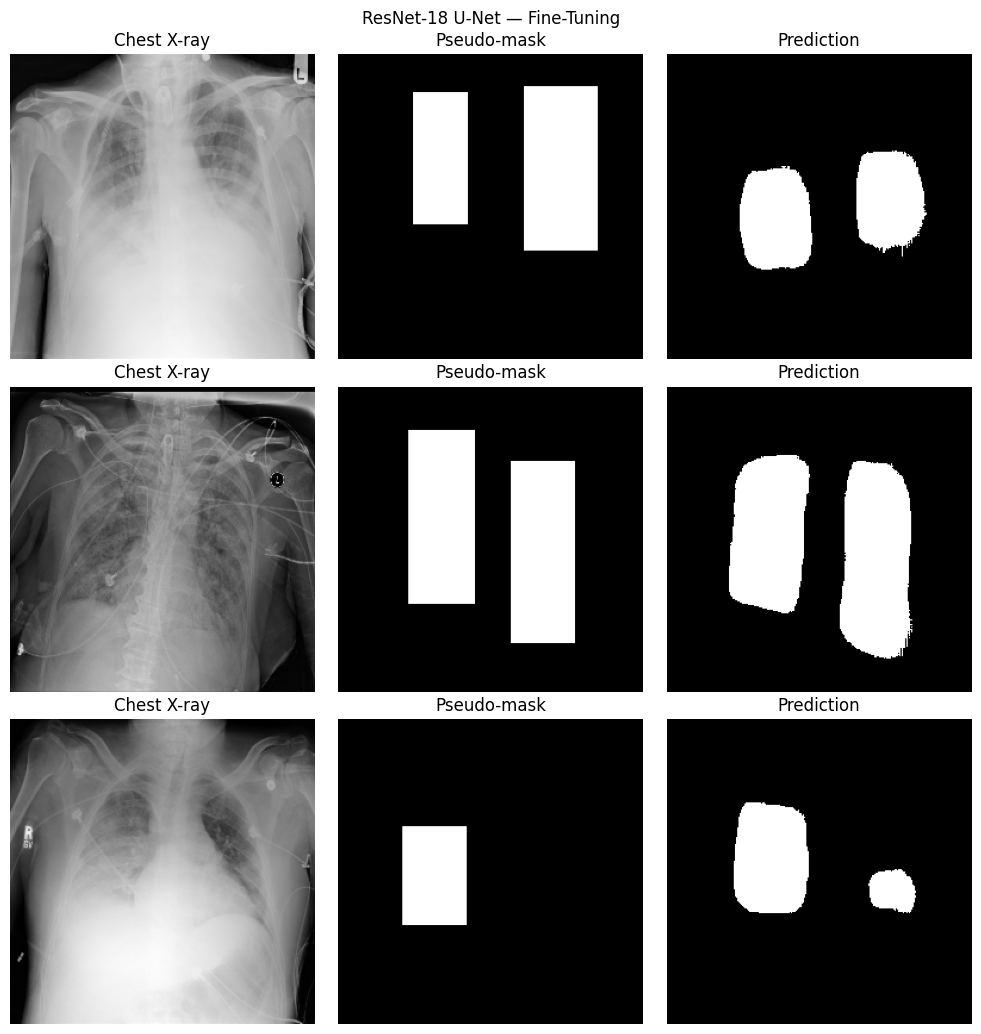

In [15]:
plot_model_history(history_resnet_ft, "ResNet18_U-Net_Fine_Tuning")
show_prediction(model_resnet_ft, "ResNet-18 U-Net — Fine-Tuning")

# 5. Comparaison finale des 4 configurations

,Modèle,Initialisation,Paramètres,Best Val IoU,Test IoU,Test Dice,Best Epoch
0,SimpleUNet,From Scratch,483153,0.462176,0.442029,0.585716,10
1,SimpleUNet,Fine-Tuning checkpoint,483153,0.470372,0.455084,0.598501,1
2,ResNet-18 U-Net,From Scratch,14321937,0.482855,0.475113,0.616938,7
3,ResNet-18 U-Net,Fine-Tuning ImageNet,14321937,0.498059,0.478659,0.623340,2


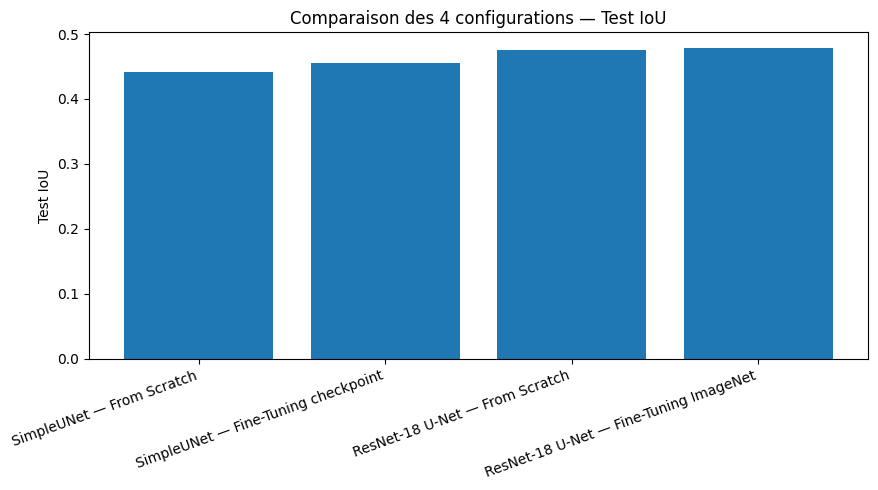

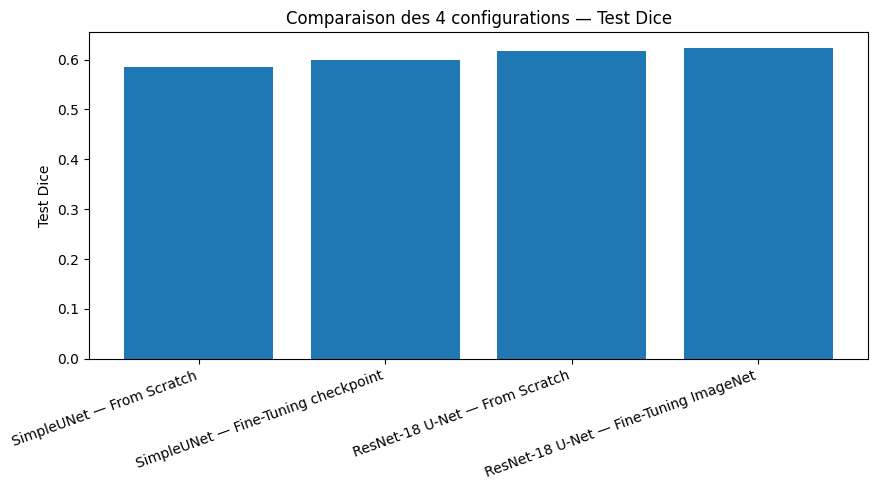

In [16]:

comparison_4 = pd.DataFrame({
    "Modèle": [
        "SimpleUNet", "SimpleUNet",
        "ResNet-18 U-Net", "ResNet-18 U-Net"
    ],
    "Initialisation": [
        "From Scratch", "Fine-Tuning checkpoint",
        "From Scratch", "Fine-Tuning ImageNet"
    ],
    "Paramètres": [
        sum(p.numel() for p in model_simple_scratch.parameters()),
        sum(p.numel() for p in model_simple_ft.parameters()),
        sum(p.numel() for p in model_resnet_scratch.parameters()),
        sum(p.numel() for p in model_resnet_ft.parameters())
    ],
    "Best Val IoU": [
        best_simple_scratch, best_simple_ft,
        best_resnet_scratch, best_resnet_ft
    ],
    "Test IoU": [
        test_iou_simple_scratch, test_iou_simple_ft,
        test_iou_resnet_scratch, test_iou_resnet_ft
    ],
    "Test Dice": [
        dice_simple_scratch, dice_simple_ft,
        dice_resnet_scratch, dice_resnet_ft
    ],
    "Best Epoch": [
        epoch_simple_scratch, epoch_simple_ft,
        epoch_resnet_scratch, epoch_resnet_ft
    ]
})

display(comparison_4)

# Test IoU
plt.figure(figsize=(9, 5))
plt.bar(
    comparison_4["Modèle"] + " — " + comparison_4["Initialisation"],
    comparison_4["Test IoU"]
)
plt.ylabel("Test IoU")
plt.title("Comparaison des 4 configurations — Test IoU")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

# Test Dice
plt.figure(figsize=(9, 5))
plt.bar(
    comparison_4["Modèle"] + " — " + comparison_4["Initialisation"],
    comparison_4["Test Dice"]
)
plt.ylabel("Test Dice")
plt.title("Comparaison des 4 configurations — Test Dice")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()


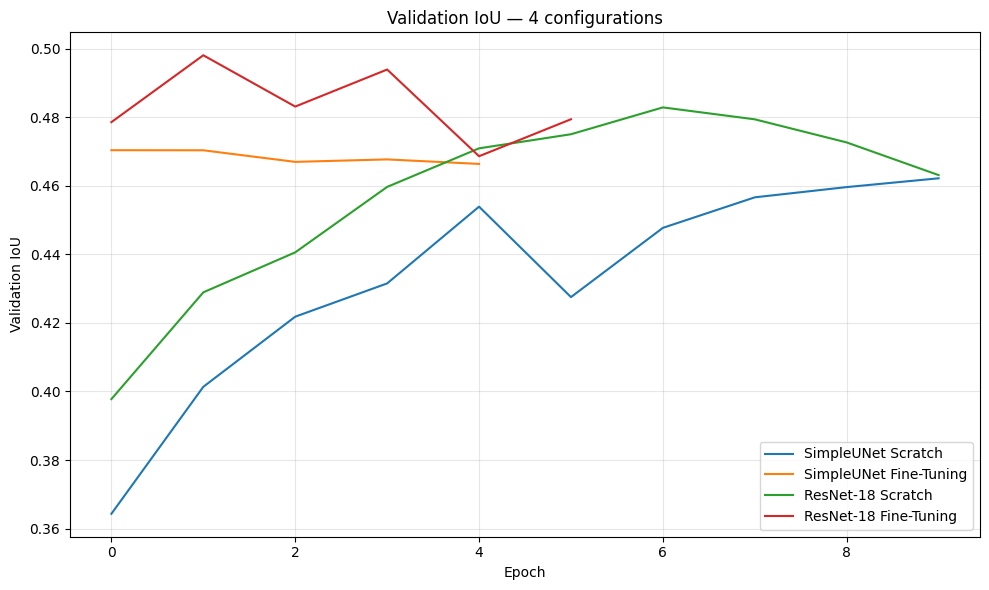

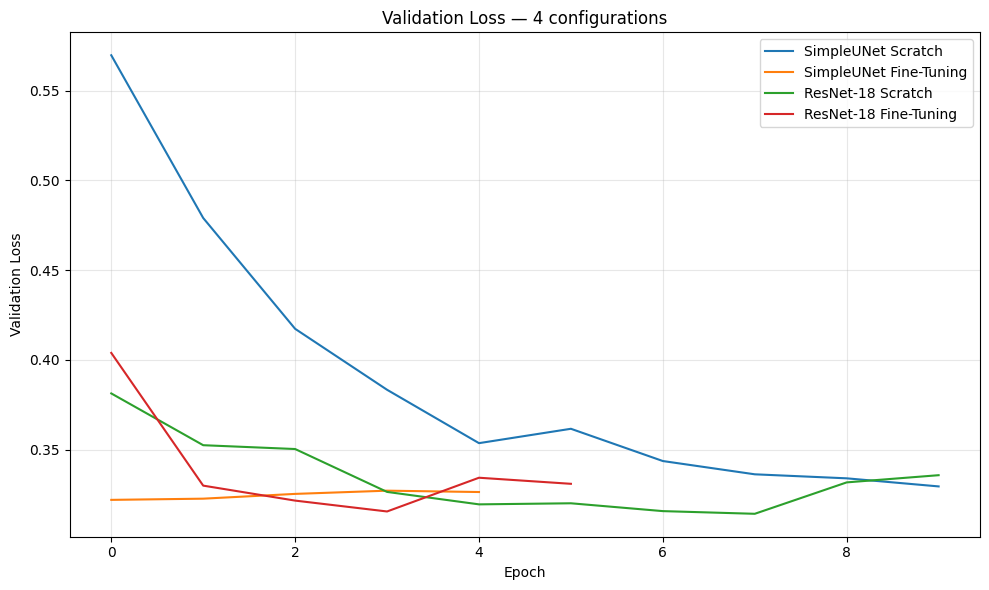

In [17]:

# Courbes comparatives — validation IoU
plt.figure(figsize=(10, 6))
plt.plot(history_simple_scratch["val_iou"], label="SimpleUNet Scratch")
plt.plot(history_simple_ft["val_iou"], label="SimpleUNet Fine-Tuning")
plt.plot(history_resnet_scratch["val_iou"], label="ResNet-18 Scratch")
plt.plot(history_resnet_ft["val_iou"], label="ResNet-18 Fine-Tuning")
plt.xlabel("Epoch")
plt.ylabel("Validation IoU")
plt.title("Validation IoU — 4 configurations")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Courbes comparatives — validation loss
plt.figure(figsize=(10, 6))
plt.plot(history_simple_scratch["val_loss"], label="SimpleUNet Scratch")
plt.plot(history_simple_ft["val_loss"], label="SimpleUNet Fine-Tuning")
plt.plot(history_resnet_scratch["val_loss"], label="ResNet-18 Scratch")
plt.plot(history_resnet_ft["val_loss"], label="ResNet-18 Fine-Tuning")
plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.title("Validation Loss — 4 configurations")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [18]:

# Analyse simple de l'overfitting à partir des courbes déjà calculées

histories = {
    "SimpleUNet Scratch": history_simple_scratch,
    "SimpleUNet Fine-Tuning": history_simple_ft,
    "ResNet-18 Scratch": history_resnet_scratch,
    "ResNet-18 Fine-Tuning": history_resnet_ft,
}

print("===== ANALYSE OVERFITTING =====")

for name, history in histories.items():
    best_idx = int(np.argmax(history["val_iou"]))
    best_val_loss = history["val_loss"][best_idx]
    final_val_loss = history["val_loss"][-1]

    overfit_signal = final_val_loss > best_val_loss

    print(f"\n{name}")
    print(f"  Meilleur Val IoU : {history['val_iou'][best_idx]:.4f} (epoch {best_idx + 1})")
    print(f"  Val Loss au meilleur IoU : {best_val_loss:.4f}")
    print(f"  Val Loss finale : {final_val_loss:.4f}")
    print(f"  Signal d'overfitting : {'OUI' if overfit_signal else 'NON'}")


===== ANALYSE OVERFITTING =====

SimpleUNet Scratch
  Meilleur Val IoU : 0.4622 (epoch 10)
  Val Loss au meilleur IoU : 0.3295
  Val Loss finale : 0.3295
  Signal d'overfitting : NON

SimpleUNet Fine-Tuning
  Meilleur Val IoU : 0.4704 (epoch 1)
  Val Loss au meilleur IoU : 0.3220
  Val Loss finale : 0.3263
  Signal d'overfitting : OUI

ResNet-18 Scratch
  Meilleur Val IoU : 0.4829 (epoch 7)
  Val Loss au meilleur IoU : 0.3157
  Val Loss finale : 0.3357
  Signal d'overfitting : OUI

ResNet-18 Fine-Tuning
  Meilleur Val IoU : 0.4981 (epoch 2)
  Val Loss au meilleur IoU : 0.3299
  Val Loss finale : 0.3309
  Signal d'overfitting : OUI
